# Grover ideal y con ruido — Primera prueba

**Objetivo.** Comprender y ejecutar una búsqueda sencilla con el algoritmo de Grover, primero sin ruido y después con un modelo de ruido despolarizante.

Trabajaremos con **2 qubits**, cuatro estados posibles (`00`, `01`, `10`, `11`) y una única solución: **`11`**. En condiciones ideales, una iteración de Grover permite obtenerla con probabilidad del 100 %.

El cuaderno está dividido en pasos cortos: preparación, circuito, ruido, simulación y comparación.

## 1. Entorno y bibliotecas

Utilizamos **Python**, **Qiskit** (para crear circuitos) y **Qiskit Aer** (para simularlos). También usaremos Matplotlib para mostrar el circuito y las gráficas.

In [1]:
from importlib.metadata import version
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

print("Qiskit:", version("qiskit"))
print("Qiskit Aer:", version("qiskit-aer"))

Qiskit: 2.6.0
Qiskit Aer: 0.17.2


## 2. Construir el circuito de Grover

En Grover intervienen tres operaciones:

1. **Superposición:** una puerta H en cada qubit prepara los cuatro estados con la misma probabilidad, $1/4$.
2. **Oráculo:** una puerta CZ marca la solución `11` cambiando el signo de su amplitud, **sin aumentar todavía su probabilidad**.
3. **Difusión:** la secuencia H–X–CZ–X–H amplifica la amplitud de la solución marcada.

Una **iteración de Grover** consiste en *oráculo + difusión*. Después medimos ambos qubits.

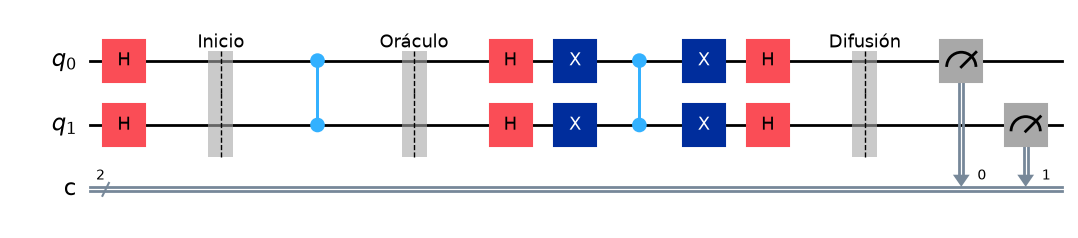

Puertas: {'h': 6, 'x': 4, 'barrier': 3, 'cz': 2, 'measure': 2}


In [2]:
def crear_grover_2q():
    circuito = QuantumCircuit(2, 2)

    # 1. Preparar la superposición uniforme
    circuito.h([0, 1])
    circuito.barrier(label="Inicio")

    # 2. Oráculo: marcar el estado |11>
    circuito.cz(0, 1)
    circuito.barrier(label="Oráculo")

    # 3. Difusor: reflexión de amplitudes (salvo fase global)
    circuito.h([0, 1])
    circuito.x([0, 1])
    circuito.cz(0, 1)
    circuito.x([0, 1])
    circuito.h([0, 1])
    circuito.barrier(label="Difusión")

    # 4. Medir
    circuito.measure([0, 1], [0, 1])
    return circuito

circuito = crear_grover_2q()
display(circuito.draw(output="mpl", style="iqp", fold=-1))
print("Puertas:", dict(circuito.count_ops()))

## 3. Definir un modelo sencillo de ruido

Utilizamos **ruido despolarizante**, un canal cuántico que mezcla parcialmente el estado con una distribución uniforme. Se puede escribir como:

$$\mathcal{E}(\rho)=(1-\lambda)\rho+\lambda\frac{I}{2^n}$$

- $\rho$ es la **matriz de densidad** del sistema.
- $\lambda$ controla la intensidad del canal.
- $n$ es el número de qubits afectados.

Los canales cuánticos también pueden describirse mediante **operadores de Kraus**: $\mathcal{E}(\rho)=\sum_j K_j\rho K_j^\dagger$.

En esta prueba aplicaremos un canal de parámetro **0,01** tras cada H o X (un qubit), y de **0,05** tras cada CZ (dos qubits). Son *parámetros del canal*, no porcentajes exactos de mediciones incorrectas. **No añadimos ruido de lectura** para aislar los errores de puertas.

In [3]:
modelo_ruido = NoiseModel()

error_1q = depolarizing_error(0.01, 1)
error_2q = depolarizing_error(0.05, 2)

modelo_ruido.add_all_qubit_quantum_error(error_1q, ["h", "x"])
modelo_ruido.add_all_qubit_quantum_error(error_2q, ["cz"])

print("Modelo de ruido preparado: H/X → 0.01; CZ → 0.05")

Modelo de ruido preparado: H/X → 0.01; CZ → 0.05


## 4. Simulación ideal y con ruido

Ejecutamos **el mismo circuito** con dos configuraciones:

- **Ideal:** sin canales de error.
- **Con ruido:** con el modelo despolarizante definido arriba.

Usamos `method="density_matrix"` **en ambos casos** para que la comparación no cambie de método de simulación. La matriz de densidad permite representar estados mixtos producidos por ruido. Fijamos `seed_simulator=42` para hacer reproducible el muestreo y `shots=1024` para repetir la medición 1.024 veces.

`transpile(..., optimization_level=0)` reduce las optimizaciones. Comprobamos que las puertas H, X y CZ siguen presentes, porque el ruido está asociado a sus nombres.

In [4]:
shots = 1024
simulador_ideal = AerSimulator(method="density_matrix", seed_simulator=42)
simulador_ruido = AerSimulator(
    method="density_matrix", noise_model=modelo_ruido, seed_simulator=42
)

circuito_compilado = transpile(circuito, simulador_ideal, optimization_level=0)
operaciones = dict(circuito_compilado.count_ops())
print("Puertas tras la transpilación:", operaciones)
if not all(operaciones.get(puerta, 0) > 0 for puerta in ("h", "x", "cz")):
    print("ATENCIÓN: revisar las puertas compiladas y el modelo de ruido.")

conteos_ideal = simulador_ideal.run(circuito_compilado, shots=shots).result().get_counts()
conteos_ruido = simulador_ruido.run(circuito_compilado, shots=shots).result().get_counts()

print("Ideal:", conteos_ideal)
print("Con ruido:", conteos_ruido)

Puertas tras la transpilación: {'h': 6, 'x': 4, 'barrier': 3, 'cz': 2, 'measure': 2}
Ideal: {'11': 1024}
Con ruido: {'11': 907, '01': 44, '10': 53, '00': 20}


## 5. Comparar la probabilidad de éxito

La solución es `11`. Su probabilidad de éxito **observada** se estima como:

$$\widehat{P}_{\mathrm{éxito}}=\frac{\text{mediciones de }11}{\text{total de mediciones}}$$

En el caso ideal esperamos el 100 %; con ruido esperamos, en general, una probabilidad inferior. Los conteos dependen del muestreo.

Probabilidad ideal: 100.00%
Probabilidad con ruido: 88.57%
Disminución observada: 11.43 puntos porcentuales


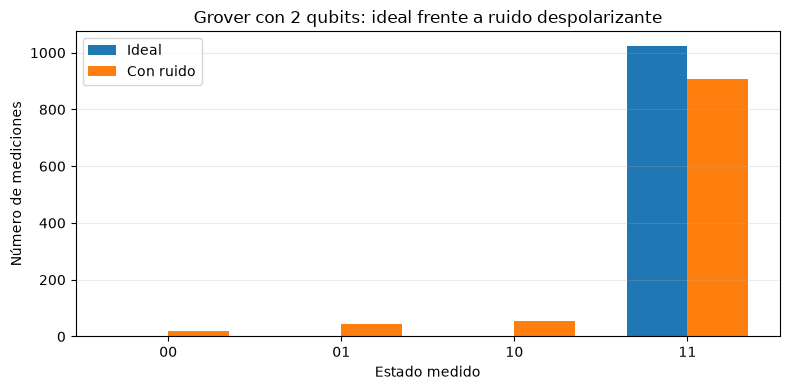

In [5]:
solucion = "11"
p_ideal = conteos_ideal.get(solucion, 0) / shots
p_ruido = conteos_ruido.get(solucion, 0) / shots

print(f"Probabilidad ideal: {p_ideal:.2%}")
print(f"Probabilidad con ruido: {p_ruido:.2%}")
print(f"Disminución observada: {(p_ideal - p_ruido) * 100:.2f} puntos porcentuales")

estados = ["00", "01", "10", "11"]
x = list(range(len(estados)))
ancho = 0.35
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([v - ancho / 2 for v in x], [conteos_ideal.get(e, 0) for e in estados],
       width=ancho, label="Ideal")
ax.bar([v + ancho / 2 for v in x], [conteos_ruido.get(e, 0) for e in estados],
       width=ancho, label="Con ruido")
ax.set_xticks(x, estados)
ax.set_xlabel("Estado medido")
ax.set_ylabel("Número de mediciones")
ax.set_title("Grover con 2 qubits: ideal frente a ruido despolarizante")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Interpretación y conclusión

- En el circuito **ideal**, la combinación de oráculo y difusión amplifica `11` hasta una probabilidad teórica del **100 %**.
- Con **ruido despolarizante**, algunas mediciones pueden producir otros estados: el canal altera la evolución cuántica.

### Conclusiones

Se ha implementado el algoritmo de Grover para un espacio de búsqueda de cuatro estados utilizando dos qubits y un oráculo que marca el estado `11`.

En condiciones ideales, una única iteración permite obtener la solución con una probabilidad del 100 %. Al introducir ruido despolarizante en las puertas cuánticas, la probabilidad de éxito disminuye y aparecen mediciones correspondientes a estados incorrectos.

Los resultados muestran que el ruido puede deteriorar la amplificación de amplitud realizada por Grover, incluso en circuitos pequeños.

Esta prueba constituye una primera validación del funcionamiento del algoritmo en condiciones ideales y bajo ruido. Para estudiar la influencia del número de iteraciones será necesario ampliar posteriormente el espacio de búsqueda y evaluar diferentes configuraciones de ruido.

**Fuentes técnicas:** [Qiskit Aer — simulador](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.AerSimulator.html) · [Qiskit Aer — canal despolarizante](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.depolarizing_error.html) · [Qiskit — visualización de circuitos](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit).